# Modeling 3 — LightGBM và so sánh trên validation

Sau baseline recency và Logistic Regression, ta thử LightGBM với cùng 18 feature. Notebook đọc train/validation qua hợp đồng đã kiểm tra, không đọc test, không bổ sung feature hay tối ưu tham số. So sánh là thăm dò POC, chưa phải đánh giá độc lập cuối cùng.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
ROOT=Path.cwd()
if ROOT.name == 'research' and ROOT.parent.name == 'notebooks': ROOT = ROOT.parent
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
if (ROOT/'.deps').is_dir(): sys.path.insert(0,str(ROOT/'.deps'))
from propensity_v2.prepared_data import load_prepared_split
from lightgbm import LGBMClassifier
import lightgbm
DATA=ROOT/'artifacts'/'data_preparation'
OUT=ROOT/'artifacts'/'research'/'modeling_lightgbm'
train,features=load_prepared_split(DATA,'train')
validation,vfeatures=load_prepared_split(DATA,'validation')
assert features==vfeatures and len(features)==18
prior=pd.read_parquet(ROOT/'artifacts'/'research'/'modeling_logistic'/'validation_predictions.parquet')
frame=validation.merge(prior,on=['household_key','snapshot_day'],validate='one_to_one',how='left',suffixes=('','_prior'))
assert len(frame)==len(validation) and frame.probability.notna().all() and frame.logistic_probability.notna().all()
assert frame.target_any_basket.eq(frame.target_any_basket_prior).all()
print('LightGBM:',lightgbm.__version__,'| Train:',len(train),'| Validation:',len(frame))

LightGBM: 4.7.0 | Train: 129834 | Validation: 27480


## 1. Huấn luyện

Cấu hình ban đầu giới hạn số lá và yêu cầu tối thiểu 100 dòng mỗi lá; đây là lựa chọn khởi đầu để giảm nguy cơ quá khớp, không bảo đảm loại bỏ overfitting. Không dùng validation để early stopping và chưa thực hiện tuning.

In [2]:
model=LGBMClassifier(n_estimators=200,learning_rate=.05,num_leaves=15,min_child_samples=100,
                     random_state=42,verbosity=-1,n_jobs=2)
model.fit(train[features],train.target_any_basket)
frame['lightgbm_probability']=model.predict_proba(frame[features])[:,1]
assert np.isfinite(frame.lightgbm_probability).all() and frame.lightgbm_probability.between(0,1).all()
print('Huấn luyện hoàn tất; xác suất chưa hiệu chỉnh.')

Huấn luyện hoàn tất; xác suất chưa hiệu chỉnh.


## 2. So sánh với baseline và Logistic Regression

Brier, log loss và ROC-AUC tính trên toàn validation. Lift được tính ở từng cutoff, lấy kỳ vọng khi đồng điểm tại ngưỡng top 10%, rồi lấy trung bình không trọng số giữa các cutoff. Các dự báo được nối trên cùng household–snapshot; kết quả không đo tác động can thiệp.

,brier,log_loss,roc_auc,weekly_lift_mean
model,,,,
Recency baseline,0.199591,0.584073,0.726843,1.313018
Logistic Regression,0.166371,0.501671,0.833017,1.777743
LightGBM,0.164389,0.495405,0.836662,1.786582


model,LightGBM,Logistic Regression,Recency baseline
snapshot_day,,,
551,1.847577,1.824954,1.329648
558,1.756754,1.756754,1.324586
565,1.770641,1.763294,1.310870
572,1.772894,1.780312,1.306429
579,1.846936,1.839208,1.320858
586,1.729660,1.736807,1.311952
593,1.773375,1.758473,1.298422
600,1.762427,1.769801,1.281908
607,1.749147,1.727282,1.308284


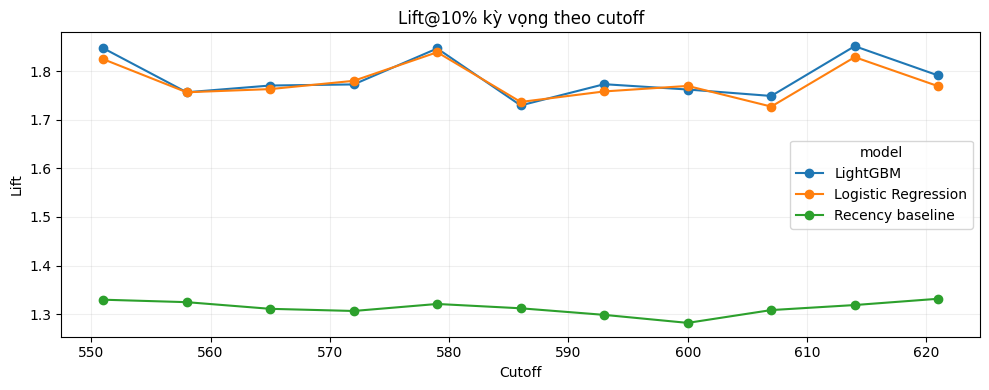

In [3]:
def expected_lift(g,col):
    y=g.target_any_basket.to_numpy();p=g[col].to_numpy()
    k=int(np.ceil(.1*len(y)));threshold=np.partition(p,len(p)-k)[len(p)-k]
    high=p>threshold;tied=p==threshold;slots=k-int(high.sum())
    precision=(y[high].sum()+slots*y[tied].mean())/k
    return precision/y.mean() if y.mean() else np.nan
results=[];weekly=[]
for name,col in [('Recency baseline','probability'),('Logistic Regression','logistic_probability'),('LightGBM','lightgbm_probability')]:
    y=frame.target_any_basket;p=frame[col]
    rows=[{'model':name,'snapshot_day':int(s),'lift':expected_lift(g,col)} for s,g in frame.groupby('snapshot_day')]
    weekly.extend(rows)
    results.append({'model':name,'brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
                    'roc_auc':roc_auc_score(y,p),'weekly_lift_mean':np.mean([r['lift'] for r in rows])})
results=pd.DataFrame(results).set_index('model');weekly=pd.DataFrame(weekly)
display(results)
display(weekly.pivot(index='snapshot_day',columns='model',values='lift'))
ax=weekly.pivot(index='snapshot_day',columns='model',values='lift').plot(marker='o',figsize=(10,4))
ax.set(title='Lift@10% kỳ vọng theo cutoff',xlabel='Cutoff',ylabel='Lift');ax.grid(alpha=.2);plt.tight_layout();plt.show()

## 3. Phạm vi diễn giải và bàn giao

Các cutoff dùng cùng household nhiều lần; nhóm có lịch sử ngắn trong validation có rất ít hộ. Tập test đã từng được xem xét trong dự án. Các kết quả validation hiện phục vụ so sánh ban đầu, chưa đủ để khẳng định giá trị kinh doanh hay chọn mô hình triển khai. Nếu cần cải thiện và hiệu chỉnh xác suất, phải dành dữ liệu phù hợp trong train/validation và đánh giá riêng.

In [4]:
OUT.mkdir(parents=True,exist_ok=True)
joblib.dump({'model':model,'features':features,'target':'target_any_basket','lightgbm_version':lightgbm.__version__},OUT/'lightgbm.joblib')
results.to_csv(OUT/'validation_comparison.csv',encoding='utf-8-sig')
weekly.to_csv(OUT/'validation_weekly_lift.csv',index=False,encoding='utf-8-sig')
frame[['household_key','snapshot_day','target_any_basket','probability','logistic_probability','lightgbm_probability']].to_parquet(OUT/'validation_predictions.parquet',index=False)
print('Đã lưu:',OUT)

Đã lưu: artifacts\modeling_lightgbm
